# Assignment 10 RNN

## Project Title:  Electric Power Consumption Forecasting using RNN and LSTM 

### Task 1 – Data Preparation


### Load, preprocess, normalize, and prepare the time-series dataset for model training.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Dropout

# Load Dataset

df = pd.read_csv(
    'household_power_consumption.txt',
    sep=';',
    low_memory=False,
    na_values=['?']
)

# Data Cleaning

df['Global_active_power'] = pd.to_numeric(
    df['Global_active_power'], errors='coerce'
)

df.dropna(subset=['Global_active_power'], inplace=True)

# Combine Date and Time

df['Datetime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    dayfirst=True
)

df.set_index('Datetime', inplace=True)

# Select Target Column

data = df[['Global_active_power']]

# Resample to Hourly Consumption

data = data.resample('h').mean()
data.dropna(inplace=True)

# Normalize Data

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(data)

# Train-Test Split (Chronological)

split = int(len(scaled_data) * 0.8)

train_data = scaled_data[:split]
test_data = scaled_data[split:]

# Sequence Generation

def create_sequences(data, time_step=24):

    X, y = [], []

    for i in range(len(data) - time_step):
        X.append(data[i:i + time_step])
        y.append(data[i + time_step])

    return np.array(X), np.array(y)

time_step = 24

X_train, y_train = create_sequences(train_data, time_step)

test_with_history = np.concatenate(
    [train_data[-time_step:], test_data]
)

X_test, y_test = create_sequences(
    test_with_history, time_step
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (27310, 24, 1)
y_train: (27310, 1)
X_test: (6834, 24, 1)
y_test: (6834, 1)


## Task 2 – RNN Model Development 

### Build and train a Recurrent Neural Network (RNN) for time-series prediction.


In [4]:
# Build RNN Model

rnn_model = Sequential([
    SimpleRNN(
        64,
        activation='tanh',
        input_shape=(time_step, 1)
    ),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(1)
])

# Compile Model

rnn_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Model Summary

rnn_model.summary()

# Train Model

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    shuffle=False
)

c:\Users\Varshini D\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0106 - mae: 0.0726 - val_loss: 0.0087 - val_mae: 0.0641
Epoch 2/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0096 - mae: 0.0684 - val_loss: 0.0088 - val_mae: 0.0636
Epoch 3/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0094 - mae: 0.0678 - val_loss: 0.0087 - val_mae: 0.0631
Epoch 4/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0094 - mae: 0.0677 - val_loss: 0.0085 - val_mae: 0.0626
Epoch 5/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0093 - mae: 0.0676 - val_loss: 0.0085 - val_mae: 0.0623
Epoch 6/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0094 - mae: 0.0675 - val_loss: 0.0088 - val_mae: 0.0634
Epoch 7/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0094 - mae: 0.0674 - val_loss: 0.0090 - val_mae: 0.0638
Epoch 8/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0094 - mae: 0.0676 - val_loss: 0.0087 - val_mae: 0.0629
Epoch 9/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - lo

## Task 3 – LSTM Model Development

### Build and train an LSTM model and compare it with the RNN model.


In [5]:
# Build LSTM Model

lstm_model = Sequential([
    LSTM(
        64,
        activation='tanh',
        input_shape=(time_step, 1)
    ),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(1)
])

# Compile Model

lstm_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Model Summary

lstm_model.summary()

# Train Model

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    shuffle=False
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0132 - mae: 0.0839 - val_loss: 0.0092 - val_mae: 0.0663
Epoch 2/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0102 - mae: 0.0716 - val_loss: 0.0091 - val_mae: 0.0657
Epoch 3/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0100 - mae: 0.0708 - val_loss: 0.0089 - val_mae: 0.0646
Epoch 4/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0096 - mae: 0.0686 - val_loss: 0.0082 - val_mae: 0.0616
Epoch 5/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0094 - mae: 0.0674 - val_loss: 0.0082 - val_mae: 0.0614
Epoch 6/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0093 - mae: 0.0671 - val_loss: 0.0083 - val_mae: 0.0619
Epoch 7/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0093 - mae: 0.0669 - val_loss: 0.0082 - val_mae: 0.0614
Epoch 8/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0092 - mae: 0.0669 - val_loss: 0.0081 - val_mae: 0.0609
Epoch 9/20
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - lo

## Task 4 – Model Evaluation 


### Evaluate both models using appropriate performance metrics and visualize actual vs. predicted values.


In [6]:
# RNN Predictions

rnn_predictions = rnn_model.predict(X_test)

# LSTM Predictions

lstm_predictions = lstm_model.predict(X_test)

# Convert Predictions to Original Scale

y_test_actual = scaler.inverse_transform(y_test)

rnn_predictions_actual = scaler.inverse_transform(
    rnn_predictions
)

lstm_predictions_actual = scaler.inverse_transform(
    lstm_predictions
)

# Evaluation Metrics

rnn_rmse = np.sqrt(
    mean_squared_error(y_test_actual, rnn_predictions_actual)
)

rnn_mae = mean_absolute_error(
    y_test_actual, rnn_predictions_actual
)

lstm_rmse = np.sqrt(
    mean_squared_error(y_test_actual, lstm_predictions_actual)
)

lstm_mae = mean_absolute_error(
    y_test_actual, lstm_predictions_actual
)

print("RNN RMSE:", rnn_rmse)
print("RNN MAE:", rnn_mae)

print("LSTM RMSE:", lstm_rmse)
print("LSTM MAE:", lstm_mae)

214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
214/214 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
RNN RMSE: 0.5278065495098981
RNN MAE: 0.36425062842862455
LSTM RMSE: 0.5186972298915012
LSTM MAE: 0.3610129896045261


### Actual vs Predicted Graph

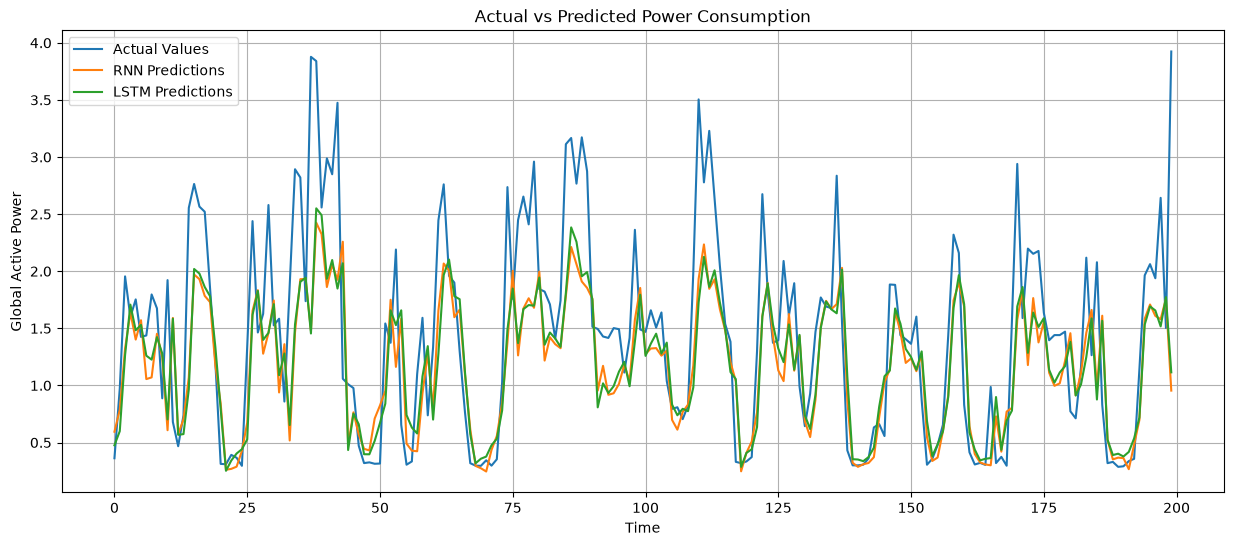

In [7]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test_actual[:200],
    label='Actual Values'
)

plt.plot(
    rnn_predictions_actual[:200],
    label='RNN Predictions'
)

plt.plot(
    lstm_predictions_actual[:200],
    label='LSTM Predictions'
)

plt.title('Actual vs Predicted Power Consumption')

plt.xlabel('Time')
plt.ylabel('Global Active Power')

plt.legend()
plt.grid()

plt.show()

### Training and Validation Loss

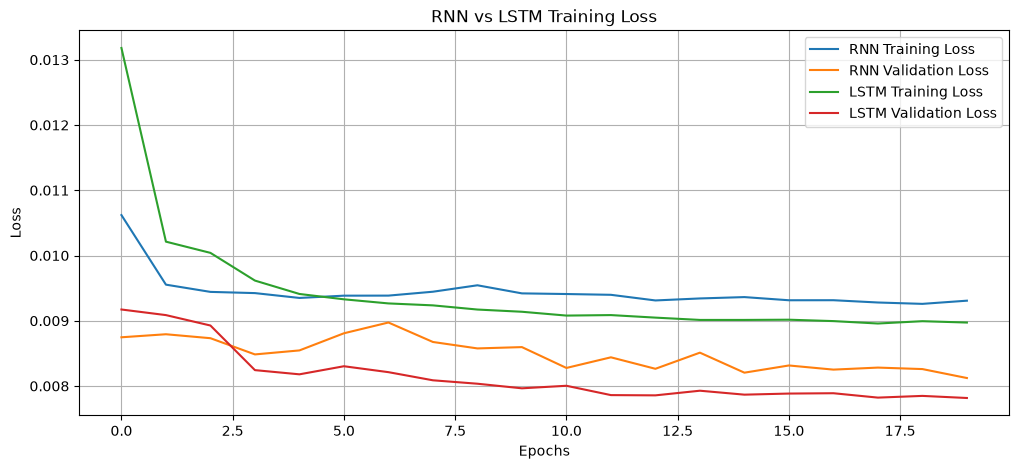

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    rnn_history.history['loss'],
    label='RNN Training Loss'
)

plt.plot(
    rnn_history.history['val_loss'],
    label='RNN Validation Loss'
)

plt.plot(
    lstm_history.history['loss'],
    label='LSTM Training Loss'
)

plt.plot(
    lstm_history.history['val_loss'],
    label='LSTM Validation Loss'
)

plt.title('RNN vs LSTM Training Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid()

plt.show()

## Task 5 – Performance Analysis


### Compare RNN and LSTM performance and discuss the impact of the vanishing gradient problem.


In [9]:
# Compare Model Performance

results = pd.DataFrame({
    'Model': ['RNN', 'LSTM'],
    'RMSE': [rnn_rmse, lstm_rmse],
    'MAE': [rnn_mae, lstm_mae]
})

print(results)

  Model      RMSE       MAE
0   RNN  0.527807  0.364251
1  LSTM  0.518697  0.361013


### Performance Comparison Graph

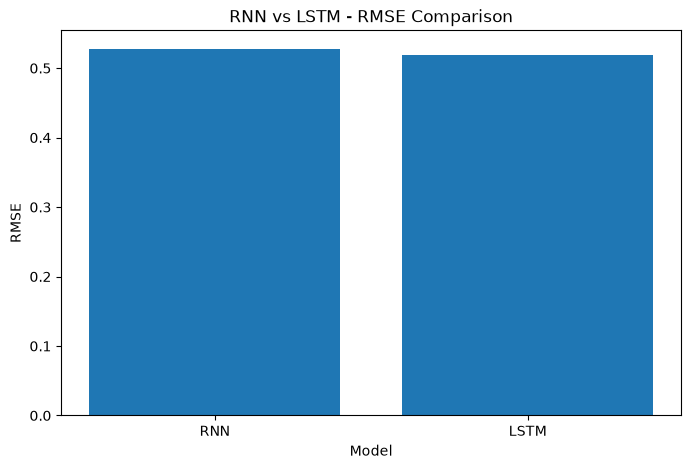

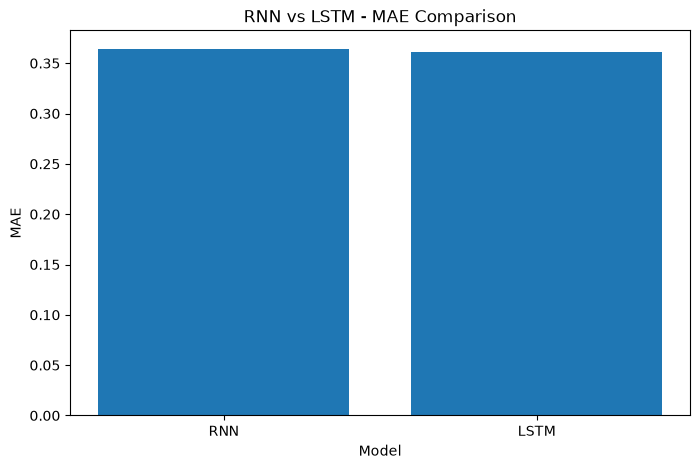

In [10]:
# RMSE Comparison

plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['RMSE']
)

plt.title('RNN vs LSTM - RMSE Comparison')

plt.xlabel('Model')
plt.ylabel('RMSE')

plt.show()


# MAE Comparison

plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['MAE']
)

plt.title('RNN vs LSTM - MAE Comparison')

plt.xlabel('Model')
plt.ylabel('MAE')

plt.show()

## Final Model Selection

In [11]:
if lstm_rmse < rnn_rmse:

    print("LSTM performs better than RNN.")

elif rnn_rmse < lstm_rmse:

    print("RNN performs better than LSTM.")

else:

    print("Both models have equal performance.")

LSTM performs better than RNN.
